# Heart Disease Machine Learning Model

**There are three main steps in creating a machine learning model:**

**1. Data Collection** - this is the systematic process of gathering, cleaning, and organizing raw information from various sources to train, test, and validate AI models/algorithms.

**2. Data Modeling** - this is the process of creating a mathematical representation of the relationships and patterns within a dataset to make predictions or uncover hidden structures.

   * **Problem Definition** - what problem are we trying to solve?
   * **Data** - what data do we have? carry out EDA (exploratory data analysis)
   * **Evaluation** - what defines success? (use evaluation metrics)
   * **Features** - what features should we model?
   * **Modelling** - what kind of model/algorithm should we use?
   * **Experiments** - what else can we try? (from this stage, you could repeat the process all over again)
    

**3. Deployment** - this is the process of integrating a trained model into a live production environment to enable it to make predictions on real-world data.

## 2.1 : Problem Definition - what problem are we trying to solve?

Following the information from the kaggle website, this data set dates from 1988 and consists of four databases: Cleveland, Hungary, Switzerland, and Long Beach V. It contains 76 attributes, including the predicted attribute, but all published experiments refer to using a subset of 14 of them. The "target" field refers to the presence of heart disease in the patient. It is integer valued 0 = no disease and 1 = disease.

From the other features in the data, we are trying to make predictions about patients if they have heart disease (1) or not(0).

## 2.2: Data - what data do we have?

We have a data with over 76 attributes, but all published experiments refer to using a subset of 14 of them. They include:

1. age
2. sex
3. chest pain type (4 values)
4. resting blood pressure
5. serum cholestoral in mg/dl
6. fasting blood sugar > 120 mg/dl
7. resting electrocardiographic results (values 0,1,2)
8. maximum heart rate achieved
9. exercise induced angina
10. oldpeak = ST depression induced by exercise relative to rest
11. the slope of the peak exercise ST segment
12. number of major vessels (0-3) colored by flourosopy
13. thal: 0 = normal; 1 = fixed defect; 2 = reversable defect

**N/B:** The names and social security numbers of the patients were recently removed from the database, replaced with dummy values.

In [3]:
#providing standard import for working with datasets
import pandas as pd
import numpy as np

#reading the heart-disease csv dataset
heart_disease_df = pd.read_csv('./data/heart-disease.csv')
heart_disease_df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [4]:
#information about the heart disease dataframe
heart_disease_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [5]:
#statistical summary of the heart disease dataframe 
heart_disease_df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


## 2.3 : Evaluation - what defines success?

If the model shows an accuracy_score greater than or equal to 0.9 or 90%, then we have successfully trained a model that can make predictions, following the 13 other important features from the dataset (asides the target column), of a patient, on whether they have heart disease or not.

## 2.4 : Features - what features should we model?

We allow our model learn patterns from all features in the dataset exclusing the target column. Here, we will look at the relationship between the features and the target column visually.

In [6]:
heart_disease_df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


**We will see the relationship between each column and the target variable**

1. Relationship between the `sex` of individuals and the `target` column
2. The relationship between the age and the trestbps of each patient
3. The relationship between males and females chestpain types (making a graph colored by the chestpain type )


In [7]:
""" From the data, we are trying to get the males/females with/without heart disease and making a plot that shows it."""

#males with or wiithout heart disease
males_with_heart_disease = len(heart_disease_df[(heart_disease_df['target'] == 1) & (heart_disease_df['sex'] == 1)])
males_without_heart_disease = len(heart_disease_df[(heart_disease_df['target'] == 0) & (heart_disease_df['sex'] == 1)])

#females with or without heart disease
females_with_heart_disease = len(heart_disease_df[(heart_disease_df['target'] == 1) & (heart_disease_df['sex'] == 0)])
females_without_heart_disease = len(heart_disease_df[(heart_disease_df['target'] == 0) & (heart_disease_df['sex'] == 0)])

"""
    We could make comparisons starting with those that have heart disease.
"""

#population with/without disease
population_with_disease = males_with_heart_disease + females_with_heart_disease
population_without_disease = males_without_heart_disease + females_without_heart_disease

#displaying each gender's distribution with heart disease and qithout heart disease
print('Males and females with heart disease: ', end='\n')
print(f'The males, approximately {males_with_heart_disease} out of {population_with_disease}, form {round((males_with_heart_disease/population_with_disease) * 100)}% of persons with heart disease.')
print(f'The females, approximately {females_with_heart_disease} out of {population_with_disease}, form {round((females_with_heart_disease/population_with_disease) * 100)}% of persons with heart disease.')

print()
print('Males and females without heart disease: ', end='\n')
print(f'The males, approximately {males_without_heart_disease} out of {population_without_disease}, form {round((males_without_heart_disease/population_with_disease) * 100)}% of persons without heart disease.')
print(f'The females, approximately {females_without_heart_disease} out of {population_without_disease}, form {round((females_without_heart_disease/population_with_disease) * 100)}% of persons without heart disease.')


Males and females with heart disease: 
The males, approximately 93 out of 165, form 56% of persons with heart disease.
The females, approximately 72 out of 165, form 44% of persons with heart disease.

Males and females without heart disease: 
The males, approximately 114 out of 138, form 69% of persons without heart disease.
The females, approximately 24 out of 138, form 15% of persons without heart disease.


In [8]:
heart_disease_df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


#### 1. Relationship between the sex of individuals and the target column

##### plot a (using fig ax, seperation of the plotting using x_female +- bar_width * 0.5 AND x_male +- bar_width * 0.5)

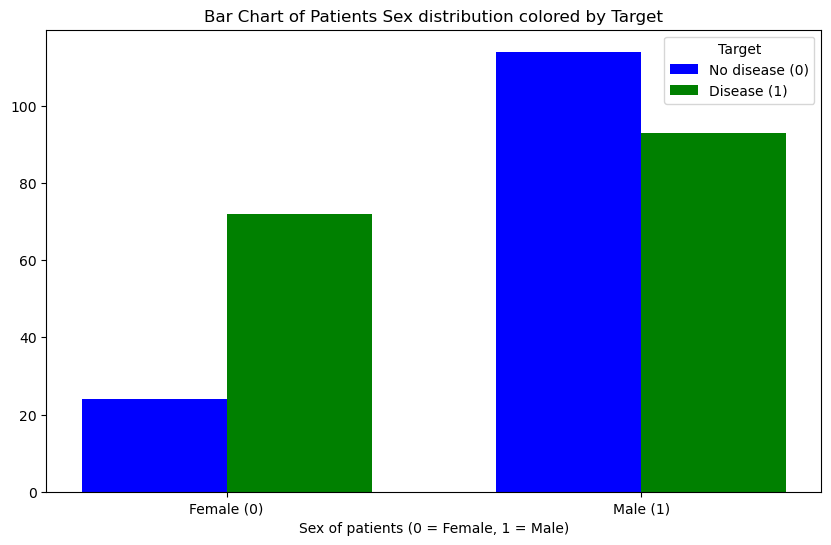

In [9]:
import matplotlib.pyplot as plt

#set your figure and axes
fig, ax = plt.subplots(figsize=(10, 6))

#each gender's distribution with heart disease and without heart disease 
males_with_heart_disease = len(heart_disease_df[(heart_disease_df['target'] == 1) & (heart_disease_df['sex'] == 1)])
males_without_heart_disease = len(heart_disease_df[(heart_disease_df['target'] == 0) & (heart_disease_df['sex'] == 1)])
females_with_heart_disease = len(heart_disease_df[(heart_disease_df['target'] == 1) & (heart_disease_df['sex'] == 0)])
females_without_heart_disease = len(heart_disease_df[(heart_disease_df['target'] == 0) & (heart_disease_df['sex'] == 0)])

#positions on the x lane: 0 = female, 1 = male and the width of the bar
x_female = 0
x_male = 1
bar_width = 0.35

# no-disease bars (target=0), offset slightly left
no_disease_plot = ax.bar(
    #the x values and then shifting them to the left of the other so that they do not overlap
    [x_female - bar_width * 0.5, x_male - bar_width * 0.5],

    #the count of the x values (height)
    [females_without_heart_disease, males_without_heart_disease],

    #the width of the bar
    width= bar_width,

    #blue color
    color='b',

    #label that the legend will show
    label='No disease (0)'
)

# disease bars (target=1), offset slightly right
disease_plot = ax.bar(
    #the x values and then shifting them to the right of the other
    [x_female + bar_width * 0.5, x_male + bar_width * 0.5],

    #the count of the x values (height)
    [females_with_heart_disease, males_with_heart_disease],

    #the width of the bar
    width= bar_width,

    #blue color
    color='g',

    #label that the legend will show
    label='Disease (1)'
)

ax.set(
    xlabel='Sex of patients (0 = Female, 1 = Male)',
    title='Bar Chart of Patients Sex distribution colored by Target',
    xticks=[0, 1],
    xticklabels=['Female (0)', 'Male (1)']
)

ax.legend(title='Target')
plt.show()

##### plot b (using crosstabs)

In [10]:
heart_disease_df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [11]:
pd.crosstab(heart_disease_df['sex'], heart_disease_df['target'], rownames=['Gender'], colnames=['Disease Status'])

Disease Status,0,1
Gender,,
0,24,72
1,114,93


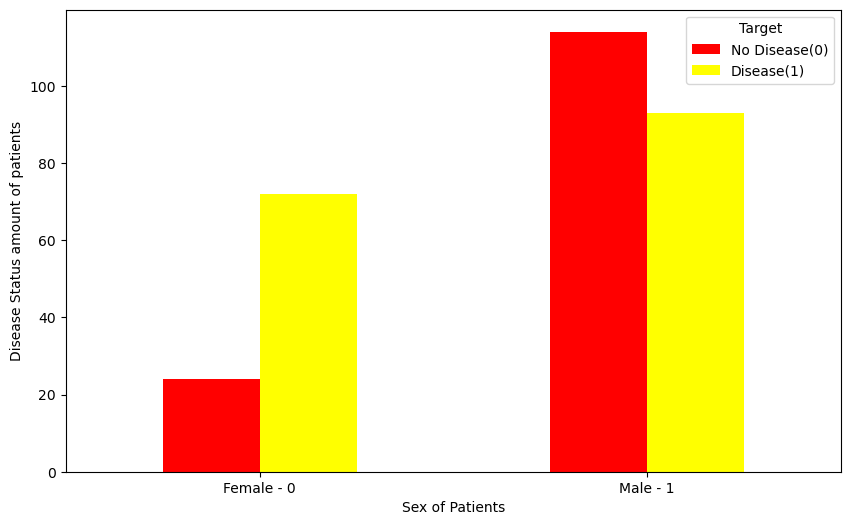

In [12]:
#the 'sex' column is seen as the x category and the column of the crosstab(the disease status)
pd.crosstab(heart_disease_df['sex'], heart_disease_df['target']).plot(kind='bar', 
                                                                      figsize=(10,6), 
                                                                      color=['red', 'yellow'], 
                                                                      label=['No Disease', 'Disease'])
plt.xlabel('Sex of Patients')
plt.ylabel('Disease Status amount of patients')
plt.xticks(rotation=0, ticks=[0, 1], labels=['Female - 0', 'Male - 1'])
plt.legend(title='Target', labels=['No Disease(0)', 'Disease(1)'])
plt.show()

#### 2. The relationship between the age and the trestbps(resting blood pressure) of each patient

In [13]:
heart_disease_df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [14]:
print('From the data: ')
print(f'Maximum age -> {max(heart_disease_df['age'])}, Minimum age -> {min(heart_disease_df['age'])}')
print(f'Maximum resting blood pressure -> {max(heart_disease_df['trestbps'])}, Minimum resting blood pressure -> {min(heart_disease_df['trestbps'])}')

From the data: 
Maximum age -> 77, Minimum age -> 29
Maximum resting blood pressure -> 200, Minimum resting blood pressure -> 94


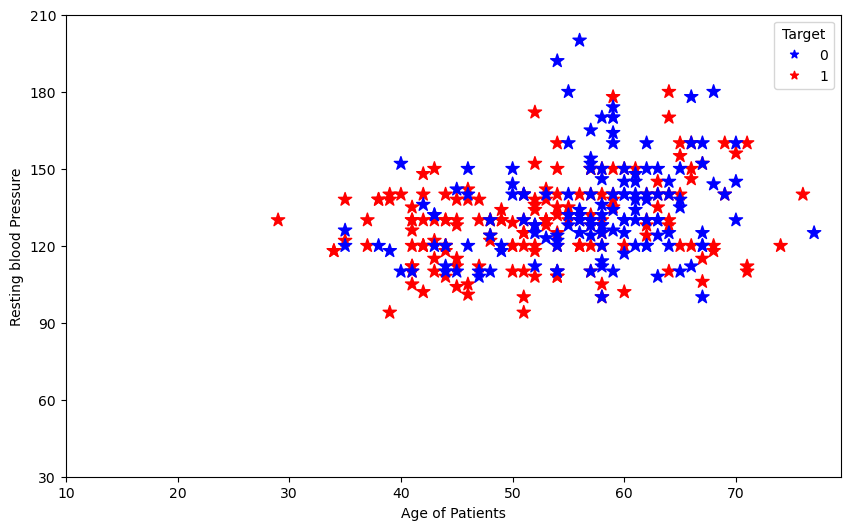

In [15]:
fig, ax = plt.subplots(
    figsize=(10, 6)
)

plot = ax.scatter(
    heart_disease_df['age'],
    heart_disease_df['trestbps'],
    s=100,
    marker='*',
    c=heart_disease_df['target'],
    cmap='bwr'
)

ax.set(
    xlabel='Age of Patients',
    ylabel='Resting blood Pressure',
    xticks=[10, 20, 30, 40, 50, 60, 70],
    yticks=[30, 60, 90, 120, 150, 180, 210],
)

ax.legend(*plot.legend_elements(), title='Target')
plt.show()


#### 3. The relationship between males and females chestpain types (making a graph colored by the chestpain type )

##### a) the plot using fig, ax

In [16]:
heart_disease_df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [17]:
heart_disease_df['cp'].value_counts()

cp
0    143
2     87
1     50
3     23
Name: count, dtype: int64

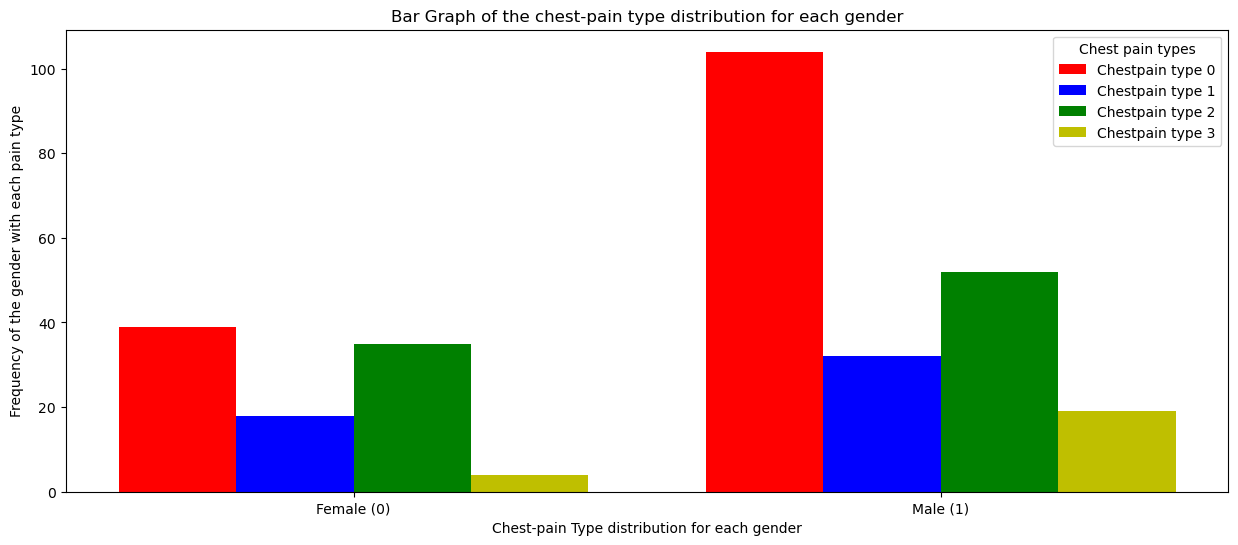

In [18]:
fig, ax = plt.subplots(figsize=(15, 6))

#males side
males_chestpain_0 = heart_disease_df[(heart_disease_df['cp'] == 0) & (heart_disease_df['sex'] == 1)]
males_chestpain_1 = heart_disease_df[(heart_disease_df['cp'] == 1) & (heart_disease_df['sex'] == 1)]
males_chestpain_2 = heart_disease_df[(heart_disease_df['cp'] == 2) & (heart_disease_df['sex'] == 1)]
males_chestpain_3 = heart_disease_df[(heart_disease_df['cp'] == 3) & (heart_disease_df['sex'] == 1)]

#females side
females_chestpain_0 = heart_disease_df[(heart_disease_df['cp'] == 0) & (heart_disease_df['sex'] == 0)]
females_chestpain_1 = heart_disease_df[(heart_disease_df['cp'] == 1) & (heart_disease_df['sex'] == 0)]
females_chestpain_2 = heart_disease_df[(heart_disease_df['cp'] == 2) & (heart_disease_df['sex'] == 0)]
females_chestpain_3 = heart_disease_df[(heart_disease_df['cp'] == 3) & (heart_disease_df['sex'] == 0)]

x_female = 0
x_male = 1
bar_width = 0.2

chestpain_0_plot = ax.bar(
    [x_female - bar_width*1.5, x_male - bar_width*1.5],
    [len(females_chestpain_0), len(males_chestpain_0)],
    width=bar_width,
    color='r',
    label = 'Chestpain type 0'
)

chestpain_1_plot = ax.bar(
    [x_female - bar_width*0.5, x_male - bar_width*0.5],
    [len(females_chestpain_1), len(males_chestpain_1)],
    width=bar_width,
    color='b',
    label = 'Chestpain type 1'
)

chestpain_2_plot = ax.bar(
    [x_female + bar_width*0.5, x_male + bar_width*0.5],
    [len(females_chestpain_2), len(males_chestpain_2)],
    width=bar_width,
    color='g',
    label = 'Chestpain type 2'
)

chestpain_3_plot = ax.bar(
    [x_female + bar_width*1.5, x_male + bar_width*1.5],
    [len(females_chestpain_3), len(males_chestpain_3)],
    width=bar_width,
    color='y',
    label = 'Chestpain type 3'
)

ax.set(
    title='Bar Graph of the chest-pain type distribution for each gender',
    xlabel='Chest-pain Type distribution for each gender',
    ylabel='Frequency of the gender with each pain type',
    xticks=[0, 1],
    xticklabels=['Female (0)', 'Male (1)']
)
ax.legend(title='Chest pain types')
plt.show()

##### b) using crosstabs

In [19]:
pd.crosstab(heart_disease_df['target'], heart_disease_df['cp'])

cp,0,1,2,3
target,,,,
0,104,9,18,7
1,39,41,69,16


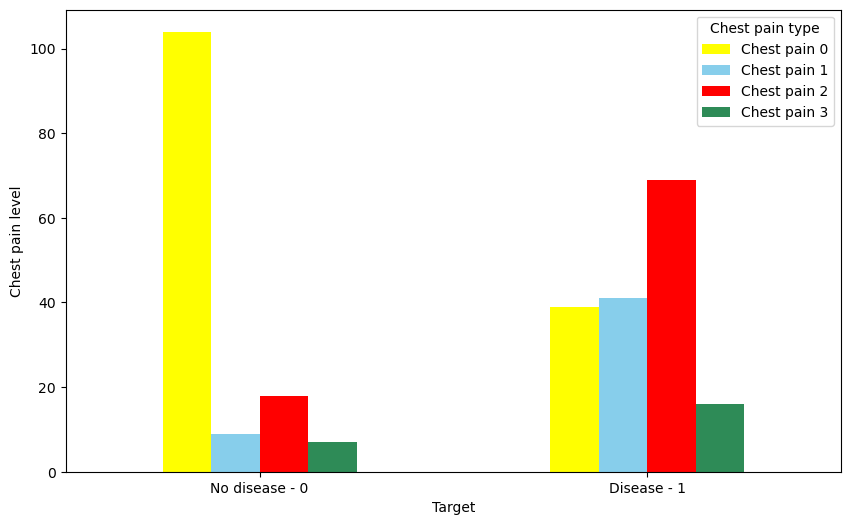

In [20]:
#the rows(target) are the 'x' placements and the colors of the chest pain are the lengend

pd.crosstab(heart_disease_df['target'], heart_disease_df['cp']).plot(kind='bar',
                                                                    color=['yellow', 'skyblue', 'red', 'seagreen'],
                                                                    xticks=[0, 1],
                                                                    xlabel='Target',
                                                                    ylabel='Chest pain level',
                                                                    figsize=(10, 6),
                                                                    )
plt.xticks(rotation=0, ticks=[0, 1], labels=['No disease - 0', 'Disease - 1'])
plt.legend(title='Chest pain type', labels=['Chest pain 0', 'Chest pain 1', 'Chest pain 2', 'Chest pain 3'])
plt.show()

## 2.5 : Modelling - what kind of model/algorithm should we use?

This is a classification problem. Therefore, we will make use of classification models. In this case, we will make use of the RandomForestClassifier from the ensemble module in scikit-learn.

### A. Using the default classification models: Logistic Regression, Linear SVC, K Neighbors Classifier, Random Forest Classifier

In [21]:
len(heart_disease_df)

303

In [29]:
#the standard imports 

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import(
        accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, precision_score, f1_score, recall_score
)

Preparing a function that takes arguments as a dictionary of models and then trains each of the model with the training and test dataset we have


In [54]:
#The modelling function
def modelling_function(models_dict, dataset, target):
    """
    This function takes 2 paramters:
    1. The dictionary/collection of models.
    2. The dataset, which is further broken down into training and test splits.
    3. Target, the column name of the dataset that holds the dependent variable, as a string.
    """
    #provide an empty dictionary that will have the models and their accuracy scores
    model_performance = {}

    #get the X and y values 
    X = dataset.drop(target, axis=1)
    y = dataset[target]

    #differentiate the training and test datasets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=49)

    #fit the models
    for model_name, model in models_dict.items():
        model.fit(X_train, y_train)
        accuracy_score = model.score(X_test, y_test)
        model_performance[model_name] = round(accuracy_score, 5)
        
    return model_performance


In [56]:
#use the modelling function
dataset = heart_disease_df
models = {
    'Logistic Regression ': LogisticRegression(max_iter=1000),
    'KNC' : KNeighborsClassifier(),
    'Linear SVC': LinearSVC(),
    'Random Forest Classifier' : RandomForestClassifier()   
}

modelling_function(models, dataset, 'target')

{'Logistic Regression ': 0.85246,
 'KNC': 0.59016,
 'Linear SVC': 0.86885,
 'Random Forest Classifier': 0.81967}

### B. Hyperparemter tuning for: Logistic Regression and Linear SVC

We would use two cross validation methods:
* RandomizedSearchCV
* Grid Search CV

#### RandomizedSearchCV function

In [67]:
def hyperparamter_tuning_randomized_cv(estimator, params_grid, dataset, target):
    """
    This function is for carrying out randomized search_cv using various parameter grid. It takes 4 arguments: 
        1. The name of the estimator and the estimator function itself, in a dictionary, as a key value pair.
        2. The estimator parameters grid
        3. The dataset to be splitted into training and test set
        4. The target column or the dependent column - as a string
    """
    best_params = dict()
    for name, model in estimator.items():
        randomized_search_cv = RandomizedSearchCV(
            model,
            params_grid,
            verbose=3,
            scoring='accuracy',
            cv=5,
            n_iter=5,
            n_jobs=-1
        )
        X = dataset.drop(target, axis=1)
        y = dataset[target]

        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
        randomized_search_cv.fit(X_train, y_train)
        best_params[name] = randomized_search_cv.best_params_
    return best_params
    

In [68]:
#Linear SVC
linear_svc = {
    'LinearSVC' : LinearSVC()
}

linear_svc_params = {
    'penalty': ['l1', 'l2'],
    'loss': ['squared_hinge'],
    'dual': [False],
    'C': [1.0],
    'max_iter': [1000, 10000]
}

linear_svc_randomized = hyperparamter_tuning_randomized_cv(linear_svc, linear_svc_params, heart_disease_df, 'target')
print(linear_svc_randomized)


/Users/edima/Desktop/heart-disease-project/env/lib/python3.13/site-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 4 is smaller than n_iter=5. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Fitting 5 folds for each of 4 candidates, totalling 20 fits
{'LinearSVC': {'penalty': 'l2', 'max_iter': 1000, 'loss': 'squared_hinge', 'dual': False, 'C': 1.0}}


In [70]:
# Logistic Regression
log_reg = {
    'LogisticRegression': LogisticRegression()
}

log_reg_params = {
    'C': [0.01, 0.1, 1.0, 10, 100],
    'solver': ['liblinear'],
    'max_iter': [1000, 10000]
}

log_reg_randomized = hyperparamter_tuning_randomized_cv(log_reg, log_reg_params, heart_disease_df, 'target')
print(log_reg_randomized)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
{'LogisticRegression': {'solver': 'liblinear', 'max_iter': 10000, 'C': 1.0}}


**Testing the tuned hyperparameters, using RandomizedSearchCV ,of Logistic Regression and LinearSVC (top 2 best performing Models)**

In [116]:
X = heart_disease_df.drop('target', axis=1)
y = heart_disease_df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [118]:
#testing with the best params(Logistic Regression)
log_reg_randomized = LogisticRegression(solver='liblinear', max_iter=1000, C=1.0)
log_reg_randomized.fit(X_train, y_train)
accuracy_score_log_reg = round(log_reg_randomized.score(X_test, y_test), 5)
print('Accuracy Score for Logistic Regression: ', accuracy_score_log_reg)

#testing with the best params(LinearSVC)
linear_svc_randomized = LinearSVC(penalty='l2', max_iter=1000, loss='squared_hinge', dual=False, C=1.0)
linear_svc_randomized.fit(X_train, y_train)
accuracy_score_lin_svc = round(linear_svc_randomized.score(X_test, y_test), 5)
print('Accuracy Score for LinearSVC: ', accuracy_score_lin_svc)

Accuracy Score for Logistic Regression:  0.86885
Accuracy Score for LinearSVC:  0.86885


#### GridSearchCV function

In [79]:
def hyperparamter_tuning_grid_cv(estimator, params_grid, dataset, target):
    """
    This function is for carrying out grid search_cv using various parameter grid. It takes 4 arguments: 
        1. The name of the estimator and the estimator function itself, in a dictionary, as a key value pair.
        2. The estimator parameters grid
        3. The dataset to be splitted into training and test set
        4. The target column or the dependent column - as a string
    """
    best_params = dict()
    for name, model in estimator.items():
        randomized_search_cv = GridSearchCV(
            model,
            params_grid,
            verbose=3,
            scoring='accuracy',
            cv=5,
            n_jobs=-1
        )
        X = dataset.drop(target, axis=1)
        y = dataset[target]

        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
        randomized_search_cv.fit(X_train, y_train)
        best_params[name] = randomized_search_cv.best_params_
    return best_params
    

In [80]:
#Linear SVC
linear_svc = {
    'LinearSVC' : LinearSVC()
}

linear_svc_params = {
    'penalty': ['l1', 'l2'],
    'loss': ['squared_hinge'],
    'dual': [False],
    'C': [1.0],
    'max_iter': [1000, 10000]
}

linear_svc_grid = hyperparamter_tuning_grid_cv(linear_svc, linear_svc_params, heart_disease_df, 'target')
print(linear_svc_grid)


Fitting 5 folds for each of 4 candidates, totalling 20 fits
{'LinearSVC': {'C': 1.0, 'dual': False, 'loss': 'squared_hinge', 'max_iter': 1000, 'penalty': 'l2'}}


In [85]:
# Logistic Regression
log_reg = {
    'LogisticRegression': LogisticRegression()
}

log_reg_params = {
    'C': [0.01, 0.1, 1.0, 10, 100],
    'solver': ['liblinear'],
    'max_iter': [1000, 10000]
}

log_reg_grid = hyperparamter_tuning_grid_cv(log_reg, log_reg_params, heart_disease_df, 'target')
print(log_reg_grid)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
{'LogisticRegression': {'C': 1.0, 'max_iter': 1000, 'solver': 'liblinear'}}


**Testing the tuned hyperparameters, using GridSearchCV ,of Logistic Regression and LinearSVC (top 2 best performing Models)**


In [102]:
#testing with the best params for Logistic Regression, using GridSearchCV
log_reg_grid = LogisticRegression(solver='liblinear', max_iter=1000, C=1.0)
log_reg_grid.fit(X_train, y_train)
print('The accuracy score for Logistic Regression: ',log_reg_grid.score(X_test, y_test))

#testing with the best params for LinearSVC, using GridSearchCV
linear_svc_grid = LinearSVC(C=1.0, dual=False, loss='squared_hinge', max_iter=1000, penalty='l2')
linear_svc_grid.fit(X_train, y_train)
linear_svc_grid.score(X_test, y_test)

The accuracy score for Logistic Regression:  0.8688524590163934


0.8688524590163934

**Making use of the Logistic Regression GridSearchCV model to carry out Model Evaluation in:**
* Accuracy_score
* Precision score
* Recall score
* F1 score
* ROC curve and AUC score

In [122]:
#imports for model evaluation using metrics
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay, accuracy_score, recall_score, precision_score, f1_score, roc_curve, roc_auc_score, RocCurveDisplay
)

#initializing y true and y preds
y_preds = log_reg_grid.predict(X_test)


In [123]:
#Accuracy score
accuracy_score = accuracy_score(y_test, y_preds)

#recall score
recall_score = recall_score(y_test, y_preds)

#precision score
precision_score = precision_score(y_test, y_preds)

#f1 score
f1_score = f1_score(y_test, y_preds)

#print statements
print('Accuracy score :', accuracy_score)
print('Recall score :', recall_score)
print('Precision score :', precision_score)
print('F1 score :', f1_score)

Accuracy score : 0.8688524590163934
Recall score : 0.875
Precision score : 0.875
F1 score : 0.875


In [125]:
roc_curve(y_test, y_preds)

(array([0.        , 0.13793103, 1.        ]),
 array([0.   , 0.875, 1.   ]),
 array([inf,  1.,  0.]))

In [126]:
roc_auc_score(y_test, y_preds)

0.8685344827586206


**Roc Curve**

* 1. Using the class, RocCurveDisplay
  2. Using the roc_curve function

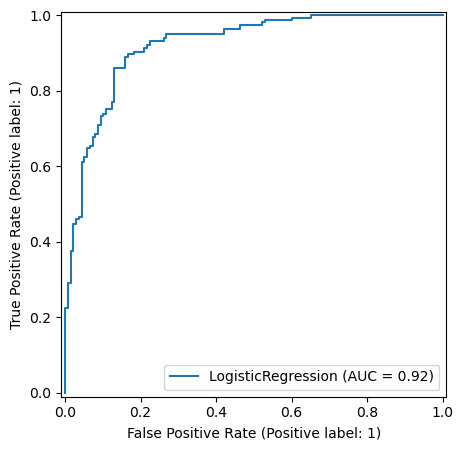

In [149]:
#roc curve plot using the RocCurveDisplay Class
fig, ax = plt.subplots(figsize=(10, 5))
RocCurveDisplay.from_estimator(log_reg_grid, X, y, ax=ax)
plt.show()

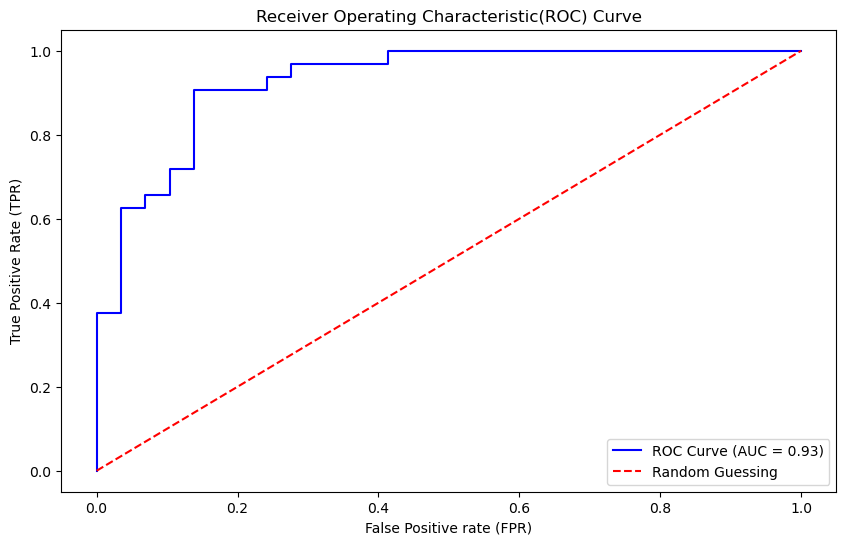

In [158]:
''' Plotting the roc curve with the roc_curve() function. '''
#getting your y_preds values that you will use for the ROC curve only
y_preds_roc = log_reg_grid.predict_proba(X_test)[:, 1]

#getting the roc_curve() function retun values and the roc_auc_score
fpr, tpr, thresholds = roc_curve(y_test, y_preds_roc)
auc_score = roc_auc_score(y_test, y_preds_roc)

#plotting the graph with the baseline and the auc_score 
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(fpr, tpr, 'b-', label=f'ROC Curve (AUC = {auc_score:.2f})')

#a baseline: a roc curve above it will a very good and predictive model, below, is the reverse
ax.plot([0, 1], [0, 1], 'r--', label='Random Guessing')

#set the values on the axes
ax.set(xlabel='False Positive rate (FPR)', 
       ylabel='True Positive Rate (TPR)', 
       title='Receiver Operating Characteristic(ROC) Curve')

#add your legend element and set it at the lowwer right of the axes
ax.legend(loc='lower right')
plt.show()

## 2.6 : Experiments - what else can we try?

### Feature Importance Check 

The 'coef_' measures how much each feature in the dataset contributes to the model's prediction of the target variable.


In [88]:
heart_disease_df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [87]:
log_reg_randomized.coef_

array([[ 0.00652372, -1.3546742 ,  0.78960096, -0.01258553, -0.00234117,
         0.12799658,  0.52331331,  0.02597976, -0.89024806, -0.61449139,
         0.66242901, -0.77067806, -0.85813632]])

The correlation matrix, on the other hand, shows us exactly how much correlation or relationship each column has with the others


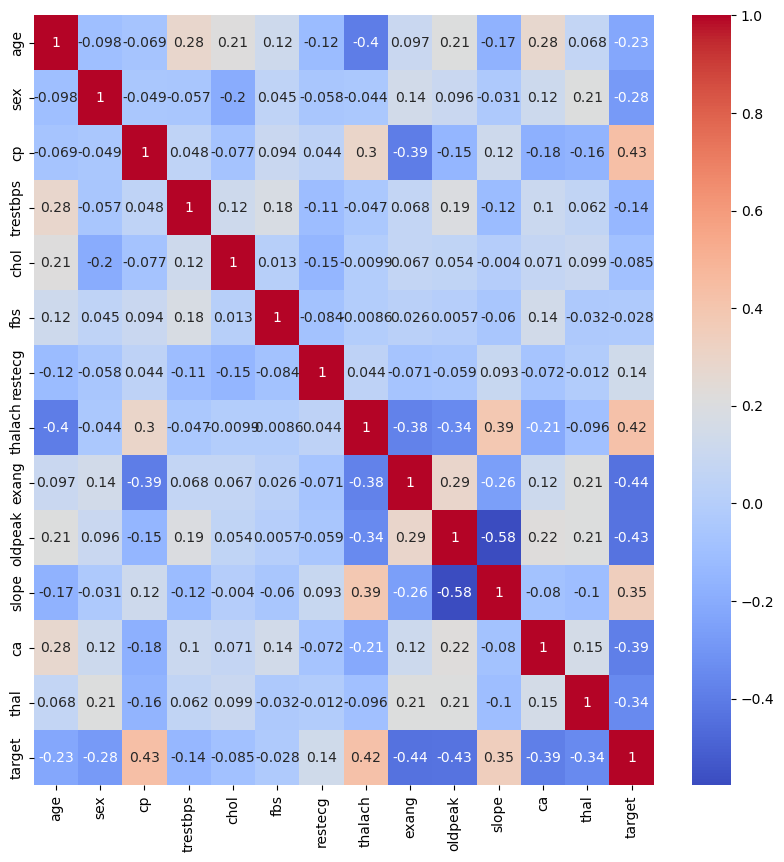

In [157]:
heart_disease_df.corr()
fig, ax = plt.subplots(figsize=(10,10))
sns.heatmap(heart_disease_df.corr(),
            cmap='coolwarm',
            annot=True,
        
)
plt.show()

#### Using other algorithms: Gradient Boosting Algorithms 

* 1. XGBoost(Extreme Gradient Boosting) -  a highly efficient and scalable gradient boosting library.
  2. CatBoost(categorical Boosting) - designed to handle categorical features efficiently.

1. XGBoost

In [159]:
pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 955.5 kB/s  0:00:02 eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [164]:
from sklearn.metrics import accuracy_score, roc_auc_score 

In [172]:
#XGBoost Classifer import, instatiation and use

#model import
from xgboost import XGBClassifier

#model instatiation
xgb = XGBClassifier()

#model use
xgb.fit(X_train, y_train)
xgb_preds = xgb.predict(X_test)
xgb_probs = xgb.predict_proba(X_test)[:, 1]

print(f"Accuracy Score using XGBoostClassifier: {accuracy_score(y_test, xgb_preds) * 100:.3f}%")
print(f'XGBoost AUC using XGBoostClassifier: {roc_auc_score(y_test, xgb_probs) * 100:.3f}%')

Accuracy Score using XGBoostClassifier: 81.967%
XGBoost AUC using XGBoostClassifier: 90.733%


2. CatBoost

In [171]:
pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.8/28.8 MB 442.8 kB/s  0:01:22m0:00:0100:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 239.4 kB/s  0:00:39 eta 0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [catboost]3/4 [catboost]
Note: you may need to restart the kernel to use updated packages.


In [180]:
#Catboost Classifer import, instatiation and use

#model import
from catboost import CatBoostClassifier

#model instatiation
cb_clf = CatBoostClassifier(iterations=200, verbose=0)

#model use
cb_clf.fit(X_train, y_train)
cb_clf_preds = cb_clf.predict(X_test)
cb_clf_probs = cb_clf.predict_proba(X_test)[:, 1]

print(f"Accuracy Score using CatBoostClassifier: {accuracy_score(y_test, cb_clf_preds) * 100:.3f}%")
print(f'XGBoost AUC using XGBoostClassifier: {roc_auc_score(y_test, cb_clf_probs) * 100:.3f}%')

Accuracy Score using CatBoostClassifier: 85.246%
XGBoost AUC using XGBoostClassifier: 91.379%
